<a href="https://colab.research.google.com/github/avflv18/evolution_simulator/blob/master/cattranslator_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q librosa tensorflow scikit-learn matplotlib

In [2]:
import os
import zipfile
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (Conv2D,MaxPooling2D,Flatten,Dense,Dropout)
print("TensorFlow version:", tf.version)

TensorFlow version: <module 'tensorflow._api.v2.version' from '/usr/local/lib/python3.13/dist-packages/tensorflow/_api/v2/version/__init__.py'>


In [1]:
def choose_file(prompt):
    """Загрузка в Colab или ввод пути в обычном Jupyter."""
    try:
        from google.colab import files
        uploaded = files.upload()
        return next(iter(uploaded))
    except ImportError:
        return input(prompt).strip()

zip_name = choose_file("Введите путь к ZIP-архиву с датасетом: " )

Saving dataset.zip to dataset.zip


In [ ]:
extract_path = "dataset"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_name, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted!")

Dataset extracted!


In [ ]:
audio_files = []
for root, dirs, files_list in os.walk(extract_path):
 for file in files_list:

    if file.lower().endswith(".wav"):

        audio_files.append(
            os.path.join(root, file)
        )
print("Audio files:", len(audio_files))

Audio files: 440


In [ ]:
def get_label(file_path):

  filename = os.path.basename(file_path)

  first_letter = filename[0].upper()

  if first_letter == "F":
    return "food"

  elif first_letter == "B":
    return "brushing"

  elif first_letter == "I":
    return "isolation"

  else:
    return None


In [ ]:
data = []
for file_path in audio_files:

  label = get_label(file_path)

  if label is not None:

    data.append({
        "file": file_path,
        "label": label
    })
df = pd.DataFrame(data)
print(df.head())
print("\nКоличество записей:")
print(len(df))
print("\nКлассы:")
print(df["label"].value_counts())


                                          file      label
0  dataset/dataset/I_DAK01_MC_FN_SIM01_303.wav  isolation
1  dataset/dataset/F_LEO01_EU_MI_RIT01_103.wav       food
2  dataset/dataset/I_BLE01_EU_FN_DEL01_219.wav  isolation
3  dataset/dataset/B_MIN01_EU_FN_BEN01_104.wav   brushing
4  dataset/dataset/I_DAK01_MC_FN_SIM01_316.wav  isolation

Количество записей:
440

Классы:
label
isolation    221
brushing     127
food          92
Name: count, dtype: int64


In [ ]:
def audio_to_mel(file_path):

 audio, sr = librosa.load(
    file_path,
    sr=16000,
    duration=4
)

 target_length = sr * 4

 if len(audio) < target_length:

    audio = np.pad(
        audio,
        (0, target_length - len(audio))
    )

 else:

    audio = audio[:target_length]

 mel = librosa.feature.melspectrogram(
    y=audio,
    sr=sr,
    n_mels=128,
    n_fft=2048,
    hop_length=512
)

 mel_db = librosa.power_to_db(
    mel,
    ref=np.max
)

 return mel_db


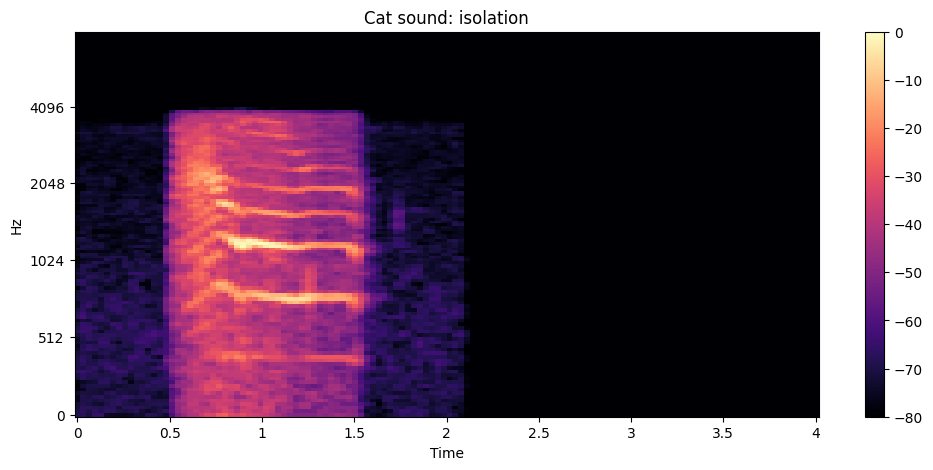

In [ ]:
mel = audio_to_mel(
    df.iloc[0]["file"]
)

plt.figure(figsize=(12, 5))

librosa.display.specshow(
    mel,
    sr=16000,
    x_axis="time",
    y_axis="mel"
)

plt.colorbar()

plt.title(
    "Cat sound: " + df.iloc[0]["label"]
)

plt.show()

In [ ]:
X = []
y = []
label_to_number = { "brushing": 0, "food": 1, "isolation": 2 }
for _, row in df.iterrows():

  try:

    mel = audio_to_mel(
        row["file"]
    )

    X.append(mel)

    y.append(
        label_to_number[row["label"]]
    )

  except Exception as e:

    print("Error:", e)
X = np.array(X)
y = np.array(y)
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (440, 128, 126)
y shape: (440,)


In [ ]:
X = []
y = []
label_to_number = {
    "brushing": 0,
    "food": 1,
    "isolation": 2
}

for _, row in df.iterrows():
    try:
        mel = audio_to_mel(row["file"])
        X.append(mel)
        y.append(label_to_number[row["label"]])
    except Exception as e:
        print("Error:", e)

X = np.array(X)
y = np.array(y)

# Conv2D ожидает: (примеры, mel-частоты, кадры-времени, каналы).
# Канал добавляется ровно один раз.
if X.ndim == 3:
    X = X[..., np.newaxis]

print("Final X shape:", X.shape)
print("Final y shape:", y.shape)

Final X shape: (440, 128, 126, 1)
Final y shape: (440,)


In [ ]:
# Проверка перед train_test_split. Эту ячейку можно запускать повторно.
if X.ndim != 4 or X.shape[-1] != 1:
    raise ValueError(f"Ожидалась форма (N, 128, time, 1), получено: {X.shape}")

print("CNN input shape:", X.shape)

CNN input shape: (440, 128, 126, 1)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", len(X_train))
print("Testing:", len(X_test))

Training: 352
Testing: 88


In [ ]:
model = Sequential([
 Conv2D(
    32,
    (3, 3),
    activation="relu",
    padding="same",
    input_shape=X_train.shape[1:]
),

 MaxPooling2D((2, 2)),

 Conv2D(
    64,
    (3, 3),
    activation="relu",
    padding="same"
),

 MaxPooling2D((2, 2)),

 Conv2D(
    128,
    (3, 3),
    activation="relu",
    padding="same"
),

 MaxPooling2D((2, 2)),

 Dropout(0.3),

 Flatten(),

 Dense(
    128,
    activation="relu"
),

 Dropout(0.4),

 Dense(
    3,
    activation="softmax"
)
])
model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 126, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 63, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 31, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 31, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 15, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 15, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 30720)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,932,288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,025,347 (15.36 MB)

 Trainable params: 4,025,347 (15.36 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Модель уже создана в предыдущей ячейке.
# Не создаём её повторно, чтобы не потерять обученные веса при повторном запуске.
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 126, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 63, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 31, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 31, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 15, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 15, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 30720)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,932,288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,025,347 (15.36 MB)

 Trainable params: 4,025,347 (15.36 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
history = model.fit(
    X_train,
    y_train,
    epochs=40,
    batch_size=16,
    validation_split=0.2
)


Epoch 1/40
18/18 ━━━━━━━━━━━━━━━━━━━━ 7s 309ms/step - accuracy: 0.3737 - loss: 18.2627 - val_accuracy: 0.5352 - val_loss: 1.0565
Epoch 2/40
18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 339ms/step - accuracy: 0.4982 - loss: 1.0534 - val_accuracy: 0.5352 - val_loss: 1.0190
Epoch 3/40
18/18 ━━━━━━━━━━━━━━━━━━━━ 5s 303ms/step - accuracy: 0.5018 - loss: 1.0448 - val_accuracy: 0.5352 - val_loss: 1.0374
Epoch 4/40
18/18 ━━━━━━━━━━━━━━━━━━━━ 10s 317ms/step - accuracy: 0.4875 - loss: 1.0673 - val_accuracy: 0.5352 - val_loss: 0.9801
Epoch 5/40
18/18 ━━━━━━━━━━━━━━━━━━━━ 10s 300ms/step - accuracy: 0.5267 - loss: 0.9456 - val_accuracy: 0.5634 - val_loss: 0.9817
Epoch 6/40
18/18 ━━━━━━━━━━━━━━━━━━━━ 10s 305ms/step - accuracy: 0.5694 - loss: 0.8970 - val_accuracy: 0.6197 - val_loss: 0.8941
Epoch 7/40
18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 347ms/step - accuracy: 0.5658 - loss: 0.9307 - val_accuracy: 0.5775 - val_loss: 1.0188
Epoch 8/40
18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 323ms/step - accuracy: 0.6050 - loss: 0.9117 - val_accuracy

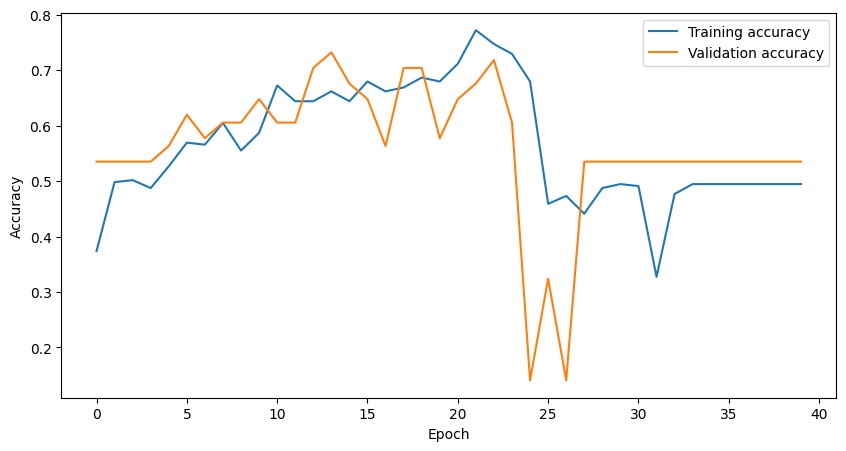

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [ ]:
loss, accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print(
    f"Test accuracy: {accuracy * 100:.2f}%"
)

Test accuracy: 50.00%


In [ ]:
predictions = model.predict(X_test)

y_pred = np.argmax(
    predictions,
    axis=1
)

class_names = [
    "brushing",
    "food",
    "isolation"
]

print(
    classification_report(
        y_test,
        y_pred,
        target_names=class_names
    )
)

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 259ms/step
              precision    recall  f1-score   support

    brushing       0.00      0.00      0.00        26
        food       0.00      0.00      0.00        18
   isolation       0.50      1.00      0.67        44

    accuracy                           0.50        88
   macro avg       0.17      0.33      0.22        88
weighted avg       0.25      0.50      0.33        88



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
model.save(
    "/content/cat_translator.keras"
)

print("🐈 Model saved!")

🐈 Model saved!


In [ ]:
my_file = choose_file("Введите путь к WAV-файлу кошки: " )

Saving kot_-_myaukane.mp3 to kot_-_myaukane.mp3


In [ ]:
mel = audio_to_mel(
    my_file
)

mel = mel[np.newaxis, ..., np.newaxis]

prediction = model.predict(
    mel,
    verbose=0
)[0]

In [ ]:
for name, probability in zip( class_names, prediction ):

   print(
    f"{name}: {probability * 100:.2f}%"
)
best_index = np.argmax(prediction)
print("\n🐈 CAT TRANSLATOR")
print("----------------------")
print( "Most likely:", class_names[best_index] )
print( "Confidence:", f"{prediction[best_index] * 100:.2f}%" )

brushing: 29.00%
food: 25.42%
isolation: 45.58%

🐈 CAT TRANSLATOR
----------------------
Most likely: isolation
Confidence: 45.58%
